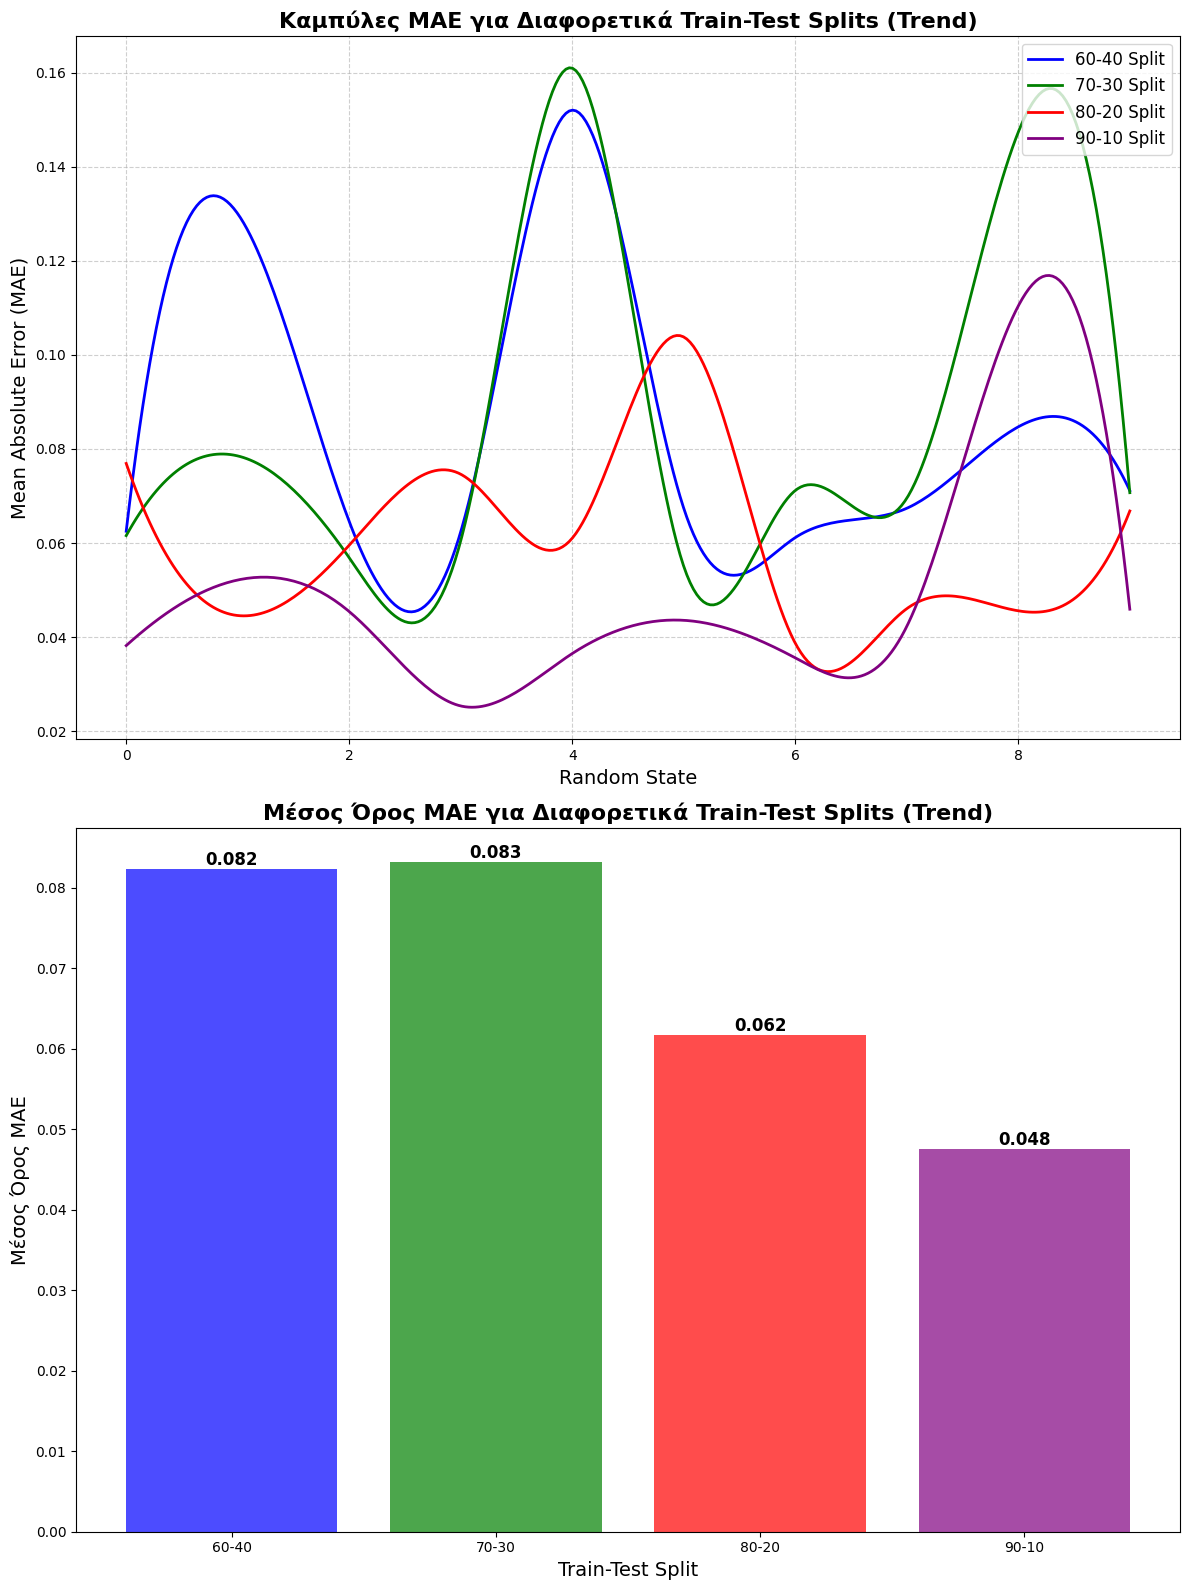

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.06250529294118819, 0.13005412349849343, 0.06456632769154284,
    0.062403318471196144, 0.15207899759613758, 0.06737091746878639,
    0.06115344634054098, 0.06739035822950742, 0.08471587868760984,
    0.07113537596983809
])
mae_70_30 = np.array([
    0.061572407063591385, 0.0785256401457505, 0.05686185113984019,
    0.06048997999104569, 0.1610140774794622, 0.05501920464544819,
    0.07117497770108369, 0.06952601958706471, 0.14742058147627435,
    0.07070424126897878
])
mae_80_20 = np.array([
    0.07692562900963491, 0.044573156513069805, 0.05953162675514443,
    0.07463427454723356, 0.061028246548563696, 0.10382759723785429,
    0.038680855928093685, 0.04603349816444519, 0.04557435284503073,
    0.06681093314231959
])
mae_90_10 = np.array([
    0.03818028645172712, 0.05213256413691426, 0.0454165738007269,
    0.02533819058341721, 0.03649038798283098, 0.04355714719261244,
    0.035568340781501964, 0.04226894671423903, 0.11044062112602271,
    0.04592091282429775
])
# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)

axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Trend)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Trend)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
